<a href="https://colab.research.google.com/github/Joyasree462/Computer-Graphics-and-Image-Processing/blob/main/Apply_the_Laplacian_mask%2C_enhanced_Laplacian_mask%2C_and_high_boost_mask_to_an_image_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
#  Import Libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [10]:
#  Upload One Image
from google.colab import files
uploaded = files.upload()

Saving image -8.webp to image -8 (1).webp


In [11]:
#  Read Image
filename = next(iter(uploaded.keys()))
img = cv2.imread(filename)

if img is None:
    raise ValueError("Image could not be loaded.")

In [12]:
#  Convert to YCrCb
ycrcb = cv2.cvtColor(img, cv2.COLOR_BGR2YCrCb)

y, cr, cb = cv2.split(ycrcb)

# Convert Y channel to float
y = y.astype(np.float32)

# : Create Laplacian Mask
lap_mask = np.array([
    [0, -1, 0],
    [-1, 4, -1],
    [0, -1, 0]
], dtype=np.float32)

In [13]:
#  Apply Laplacian Mask
laplacian = cv2.filter2D(
    y, cv2.CV_32F, lap_mask
)

# Display Laplacian response
lap_result = cv2.normalize(
    np.abs(laplacian),
    None, 0, 255,
    cv2.NORM_MINMAX
).astype(np.uint8)

In [14]:
#  Enhanced Laplacian Mask
enhanced_mask = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype=np.float32)

enhanced_y = cv2.filter2D(
    y, cv2.CV_32F, enhanced_mask
)

enhanced_y = np.clip(
    enhanced_y, 0, 255
).astype(np.uint8)

# High-Boost Mask
A = 1.5

highboost_mask = np.array([
    [-1, -1, -1],
    [-1, A + 8, -1],
    [-1, -1, -1]
], dtype=np.float32)

highboost_y = cv2.filter2D(
    y, cv2.CV_32F, highboost_mask
)

highboost_y = np.clip(
    highboost_y, 0, 255
).astype(np.uint8)


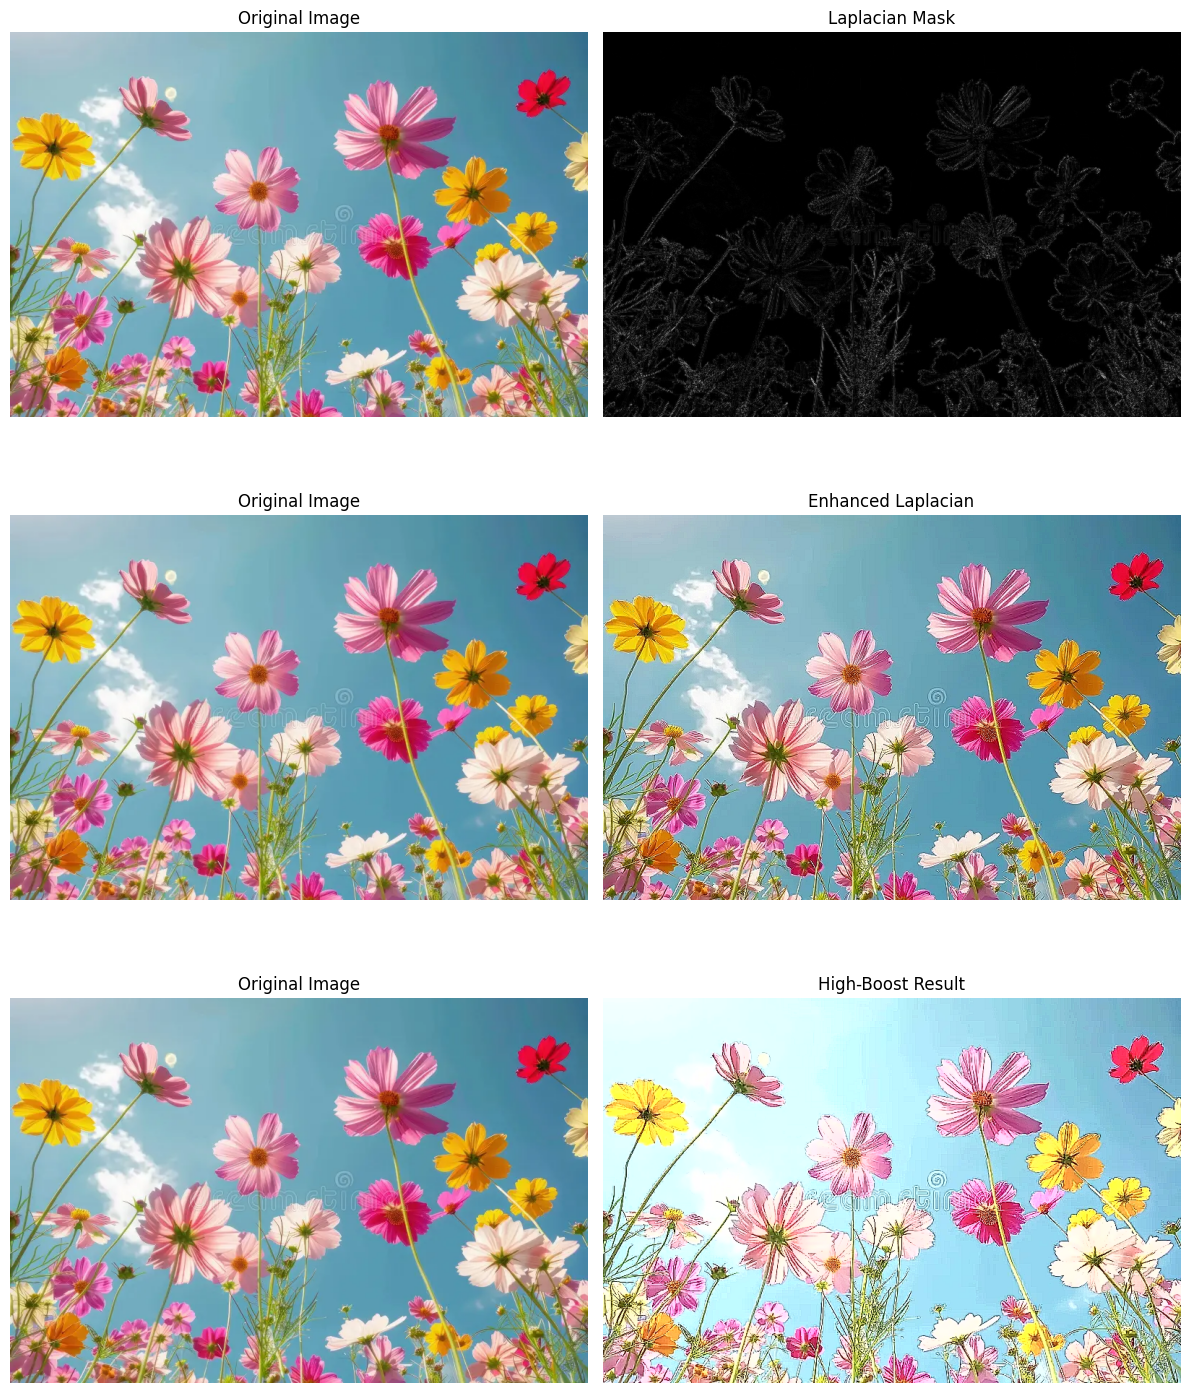

In [15]:
#  Convert Results Back to Colour
enhanced_img = cv2.cvtColor(
    cv2.merge([enhanced_y, cr, cb]),
    cv2.COLOR_YCrCb2RGB
)

highboost_img = cv2.cvtColor(
    cv2.merge([highboost_y, cr, cb]),
    cv2.COLOR_YCrCb2RGB
)

# Original Image in RGB
original = cv2.cvtColor(
    img, cv2.COLOR_BGR2RGB
)

#  Display Original and Results
fig, axes = plt.subplots(3, 2, figsize=(12, 15))

# Row 1: Laplacian
axes[0, 0].imshow(original)
axes[0, 0].set_title("Original Image")
axes[0, 0].axis('off')

axes[0, 1].imshow(lap_result, cmap='gray')
axes[0, 1].set_title("Laplacian Mask")
axes[0, 1].axis('off')

# Row 2: Enhanced Laplacian
axes[1, 0].imshow(original)
axes[1, 0].set_title("Original Image")
axes[1, 0].axis('off')

axes[1, 1].imshow(enhanced_img)
axes[1, 1].set_title("Enhanced Laplacian")
axes[1, 1].axis('off')

# Row 3: High-Boost
axes[2, 0].imshow(original)
axes[2, 0].set_title("Original Image")
axes[2, 0].axis('off')

axes[2, 1].imshow(highboost_img)
axes[2, 1].set_title("High-Boost Result")
axes[2, 1].axis('off')
plt.tight_layout()
plt.show()
